# Model 10: Monte Carlo Simulation of Rehearsal and Forgetting

## Objective
Investigate how rehearsal probability affects long-term synaptic strength using repeated stochastic simulations.

## Hypothesis
Increasing rehearsal probability will increase average final connection strength and the probability of remaining above a specified memory threshold.

In [9]:

import numpy as np
import matplotlib.pyplot as plt

def simulate_memory(p, steps, eta, decay, initial_weight, rng):
    weight = initial_weight

    for t in range(steps):
        if rng.random() < p:
            weight += eta * (1 - weight)
        else:
            weight -= decay * weight

    return weight


In [10]:

# Parameters from Model 9
steps = 500
eta = 0.05
decay = 0.01
initial_weight = 0.1

# New experimental parameters
num_trials = 1000
probabilities = np.linspace(0.01, 0.25, 25)
threshold = 0.5

rng = np.random.default_rng(42)

means = []
stds = []
retention_rates = []

for p in probabilities:
    final_weights = []

    for trial in range(num_trials):
        final_weight = simulate_memory(
            p, steps, eta, decay, initial_weight, rng
        )
        final_weights.append(final_weight)

    final_weights = np.array(final_weights)

    means.append(np.mean(final_weights))
    stds.append(np.std(final_weights))
    retention_rates.append(np.mean(final_weights >= threshold))


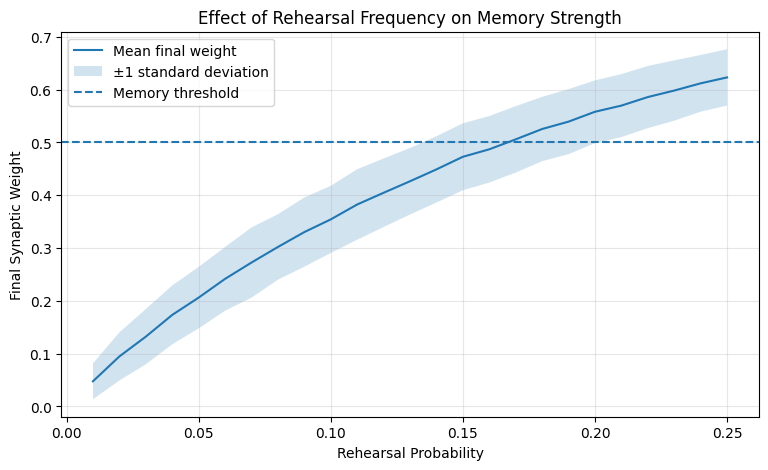

In [11]:

plt.figure(figsize=(9, 5))

plt.plot(probabilities, means, label="Mean final weight")
plt.fill_between(
    probabilities,
    np.array(means) - np.array(stds),
    np.array(means) + np.array(stds),
    alpha=0.2,
    label="±1 standard deviation"
)

plt.axhline(threshold, linestyle="--", label="Memory threshold")

plt.xlabel("Rehearsal Probability")
plt.ylabel("Final Synaptic Weight")
plt.title("Effect of Rehearsal Frequency on Memory Strength")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


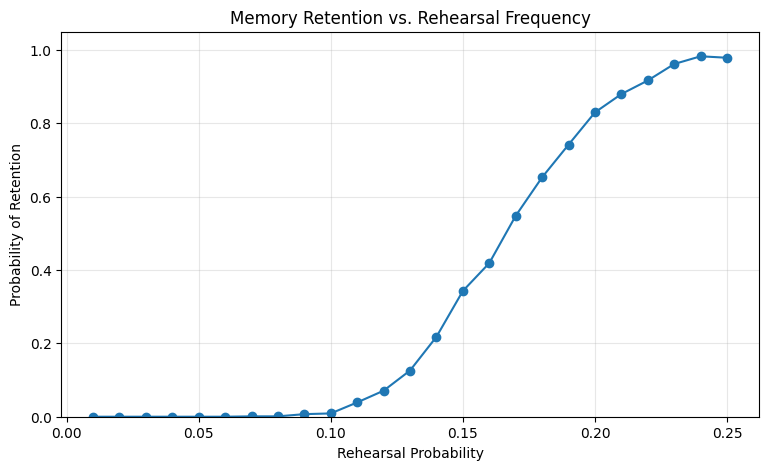

In [12]:

plt.figure(figsize=(9, 5))

plt.plot(probabilities, retention_rates, marker="o")

plt.xlabel("Rehearsal Probability")
plt.ylabel("Probability of Retention")
plt.title("Memory Retention vs. Rehearsal Frequency")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.show()



## Results and Interpretation

### Experiment 1: Average Synaptic Strength

The first graph demonstrates a positive relationship between rehearsal probability and average final synaptic strength.

**Key observations:**
- Increasing rehearsal probability leads to higher average synaptic weights.
- The relationship exhibits diminishing returns, as the rate of increase slows at higher rehearsal probabilities.
- The shaded region (±1 standard deviation) demonstrates variability between individual simulations.
- Average synaptic strength crosses the memory retention threshold of 0.5 at approximately $p = 0.17$.

### Experiment 2: Memory Retention Probability

The second graph shows the proportion of simulations in which the final synaptic weight exceeds the retention threshold.

**Key observations:**
- At low rehearsal probabilities ($p < 0.10$), memory retention is extremely unlikely.
- Between approximately $p = 0.13$ and $p = 0.20$, retention probability increases rapidly.
- At high rehearsal probabilities ($p > 0.23$), retention probability approaches 1.
- The resulting S-shaped curve suggests a transition region between predominantly forgotten and predominantly retained memories.

### Interpretation

These results suggest that rehearsal frequency plays a significant role in determining long-term memory retention within our simulated model.

Rather than exhibiting a sharp threshold, the system demonstrates a gradual probabilistic transition. Individual memories may still be forgotten at relatively high rehearsal probabilities due to the stochastic nature of the simulation.

Importantly, these results are specific to our chosen learning rate, decay rate, simulation duration, and retention threshold. They do not establish a universal rehearsal frequency required for human memory retention.

## Next Step: Theoretical Analysis

Our simulations suggest that the expected synaptic weight approaches a stable value determined by the balance between reinforcement and decay.

We will derive this equilibrium mathematically and compare the theoretical predictions against our Monte Carlo results.

**Research question:** Can we predict the average long-term synaptic weight, and the rehearsal probability required to maintain it above a specified threshold, without running simulations?


## Theoretical Equilibrium Derivation

To determine the long-term expected synaptic strength,
we set the expected change in weight equal to zero.

![Equilibrium Derivation](images/equilibrium_derivation.png)

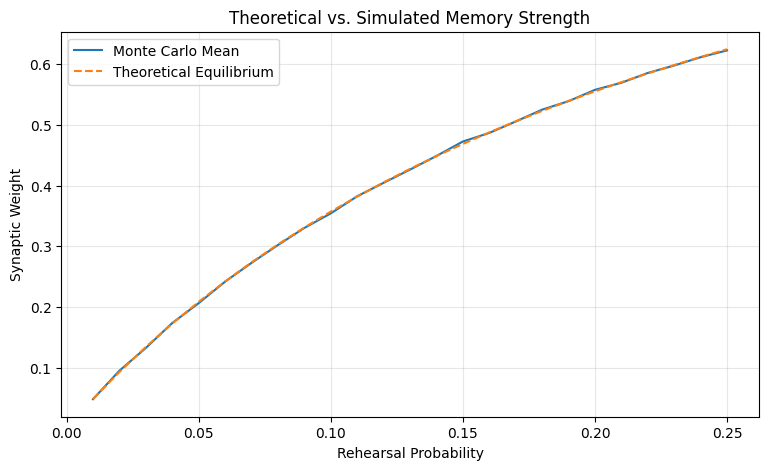

In [13]:

theoretical_weights = (
    probabilities * eta /
    (probabilities * eta + (1 - probabilities) * decay)
)

plt.figure(figsize=(9, 5))

plt.plot(probabilities, means, label="Monte Carlo Mean")
plt.plot(probabilities, theoretical_weights,
         "--", label="Theoretical Equilibrium")

plt.xlabel("Rehearsal Probability")
plt.ylabel("Synaptic Weight")
plt.title("Theoretical vs. Simulated Memory Strength")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [14]:

# Compare simulated means to theoretical predictions
errors = np.array(means) - theoretical_weights

mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors ** 2))
max_error = np.max(np.abs(errors))

print(f"Mean Absolute Error: {mae:.6f}")
print(f"Root Mean Squared Error: {rmse:.6f}")
print(f"Maximum Absolute Error: {max_error:.6f}")


Mean Absolute Error: 0.001234
Root Mean Squared Error: 0.001555
Maximum Absolute Error: 0.004031



## Theoretical Validation

The Monte Carlo simulations closely match the theoretical
equilibrium predictions across the tested rehearsal probabilities.

The theoretical equilibrium is given by:

$$
w^* = \frac{p\eta}{p\eta + (1-p)\lambda}
$$

The close agreement between the simulated means and theoretical
equilibrium supports the mathematical consistency of the model.

Small differences arise from stochastic variation, finite sample
size, and potentially incomplete convergence to equilibrium.



## Final Results and Conclusions

### Error Analysis

The Monte Carlo simulations demonstrated close agreement with
the theoretical equilibrium predictions.

The calculated errors were:

- **Mean Absolute Error (MAE):** 0.001234
- **Root Mean Squared Error (RMSE):** 0.001555
- **Maximum Absolute Error:** 0.004031

These results indicate that the simulated average synaptic
weights closely approximate the theoretical long-run expected
weights across the tested rehearsal probabilities.

### Critical Rehearsal Probability

Using the equilibrium equation, we derived a critical
rehearsal probability of:

$$
p_c = \frac{1}{6} \approx 0.1667
$$

For our selected parameters, a rehearsal probability of
approximately 16.67% produces an expected equilibrium
synaptic weight of 0.5.

This prediction agrees with the threshold crossing observed
in the Monte Carlo simulations.

### Conclusions

1. Increasing rehearsal probability increases average
   long-term synaptic strength.

2. Memory retention probability exhibits an S-shaped
   transition as rehearsal frequency increases.

3. The theoretical equilibrium accurately predicts the
   average behavior of the stochastic simulation.

4. The critical rehearsal probability depends on the
   learning rate, decay rate, and chosen retention threshold.

### Limitations

The model represents memory using a single synaptic weight,
with constant learning and decay rates and independent
rehearsal events.

The close agreement between theory and simulation validates
the implementation of these mathematical assumptions,
but does not establish biological accuracy.

### Future Directions

Future models will investigate networks of interacting
neurons, distributed memory representations, and how
learning and forgetting emerge from network dynamics.
